# Configuración de Perifericos:


## Timers

- TIM2 a TIM7, TIM12 a TIM14 cuelgan de APB1. El reloj del bus corre a 45 MHz, pero el multiplicador interno del timer lo eleva a 90 MHz.

- TIM1, TIM8 a TIM11 cuelgan de APB2. El reloj del bus corre a 90 MHz y el timer opera a 180 MHz.

El tiempo de evento del timer lo calculo como:

$$T = \frac{(Prescaler \space + \space 1) \space  \space (AutoReloadRegister)}{f_{APB1/2}}$$

### Ejemplo:

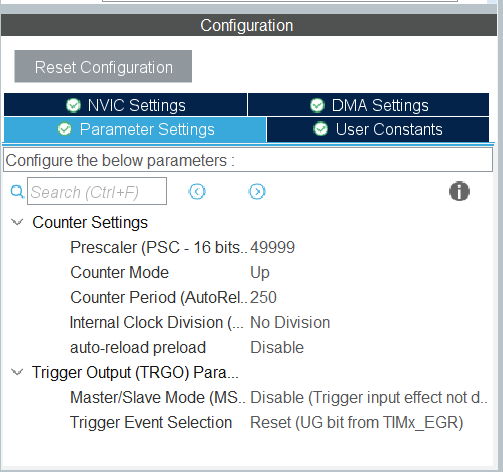

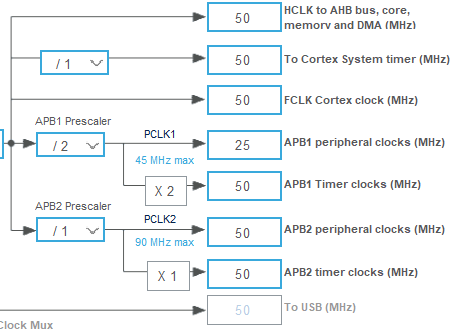

En este caso tengo la configuración del Timer3, el cual cuelga del APB1, yo lo puse a 50MHz si quiero que el timer cuente 250ms pongo un Preescaler de 49999 para que cuente en milisegundos y luego pongo 250 en el AutoReloadRegister:

$$T = \frac{(49999 + 1) \space  \space 250}{50MHz} = 250ms $$

Para activar las interrupciones voy a la pestaña de NVIC y activo la casilla. Después en el código lo comando con la siguiente primitiva weak:

Luego siempre inicializo los Timers con HAL_TIM_Base_Start_IT(&htim#) donde # es el numero de timer a inicializar. 

Otra carácteristica es el Output Compare de los timers, para esto lo que hacemos es configurar una patita del micro como TIM2_CH1 (el timer 2 tiene esta función):

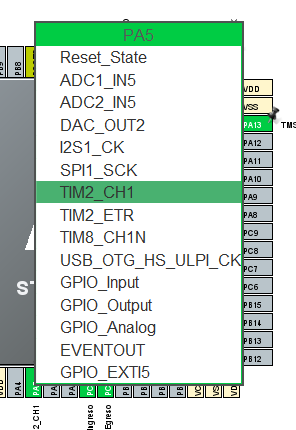

Luego en la configuración del timer 2:

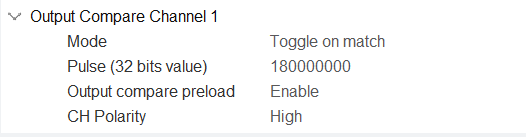

### Donde:

### 1- Mode:

- Toggle on match: El pin invierte su estado lógico (si estaba en bajo pasa a alto; si estaba en alto pasa a bajo). Es ideal para generar ondas cuadradas al 50% de ciclo de trabajo sin intervención de software.   

- Set active on match: Fuerza el pin al estado lógico activo (según la polaridad definida).

- Set inactive on match: Fuerza el pin al estado lógico inactivo (nivel bajo en polaridad High).

- Frozen: La coincidencia no altera físicamente el pin. Se utiliza cuando solo se requiere la interrupción o el disparo hacia otro periférico/DMA sin conmutar un pin externo.

- Timing: Similar a Frozen, puramente referencial para marcas de tiempo internas.

### 2- Pulse:

Representa el valor cargado en el registro de comparación CCR1 (Capture/Compare Register 1).   

- Indica el número de cuentas de reloj del timer que deben transcurrir para que ocurra el evento de coincidencia (match) con el contador CNT.

- Al indicar (32 bits value), confirma que estás configurando un timer de 32 bits (en la Nucleo-F446RE esto corresponde a TIM2 o TIM5; los demás son de 16 bits).

- **Nota:** Para que la coincidencia suceda, este valor debe ser menor o igual al periodo del timer (ARR). Si Pulse es mayor que ARR, el contador se reiniciará a 0 antes de alcanzarlo y el pin nunca conmutará (a menos que el contador cuente en sentido descendente según el modo).

### 3- Output Compare Preload:

Controla el bit OC1PE (Output Compare 1 Preload Enable) en el registro TIMx_CCMR1:   

- Enable: El valor que escribas en CCR1 (ya sea desde el .ioc o en tiempo de ejecución con __HAL_TIM_SET_COMPARE) entra en un registro intermedio (shadow register) y solo se transfiere al registro activo cuando ocurre un evento de actualización (Update Event o desbordamiento del timer). Se recomienda cuando se sincronizan cambios con el periodo general.

- Disable: Cualquier escritura en CCR1 tiene efecto inmediato. Es el modo requerido si implementas conmutación dinámica o trenes de pulsos sumando un offset dentro del callback de interrupción de Output Compare.

### 4- CH Polarity:

Configura el bit CC1P en el registro TIMx_CCER, definiendo qué nivel de tensión representa el estado "activo" en el pin de salida:   

- High: Nivel activo = Alto (V_DD / 3.3 V); nivel inactivo = Bajo (GND / 0 V).

- Low: Nivel activo = Bajo (0 V); nivel inactivo = Alto (3.3 V). La lógica de salida se invierte por completo

En el código lo inicializo como: *HAL_TIM_OC_Start_IT(&htim#, TIM_CHANNEL_1)* y atiendo las interrupciones como:

## ADC

Tenemos los siguientes parámetros para configurar el ADC:

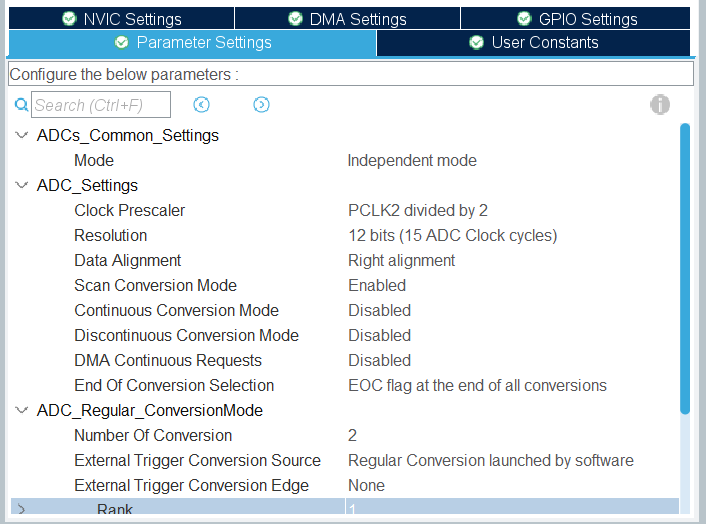

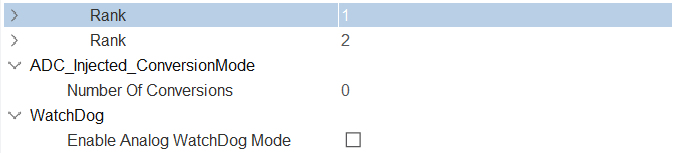

### ADC_Settings

- Clock Prescaler: Factor de división del reloj APB2 (PCLK2 divided by 4, etc.). Determina $f_{ADC}$.

- Resolution: Opciones de 12 bits, 10 bits, 8 bits o 6 bits. A menor resolución, menor tiempo de conversión.

- Data Alignment:

  - Right alignment (típico): El dato de 12 bits se alinea a la derecha (valores de $0$ a $4095$ en un entero de 16 bits).


  - Left alignment: Justificado a la izquierda (útil para procesado rápido donde interesan los bits más significativos).
 
- Scan Conversion Mode:

    - Disabled: Muestrea un único canal regular.

    - Enabled: Obligatorio si se configura más de un canal en la secuencia regular, barriendo de forma ordenada cada entrada.
 
- Continuous Conversion Mode:

    - Enabled: El ADC reinicia automáticamente una nueva conversión en cuanto termina la anterior.

    - Disabled: Convierte solo tras un disparo explícito (por software o por timer/hardware).
 
- Discontinuous Conversion Mode: Permite ejecutar grupos parciales de canales por cada trigger en lugar de barrer la secuencia completa.

### ADC_Regular_ConversionMode

- Number Of Conversion: Cantidad de canales que integran la secuencia (Rank 1, Rank 2, etc.).

- External Trigger Conversion Source: Origen del disparo de inicio:

    - Regular Conversion launched by software: Disparo manual mediante funciones HAL.

    - Timer X Trigger Out event: Sincronización exacta con timers (TRGO) para muestreo a tasa fija sin carga de CPU ni jitter.

    - External pin: Disparo por flanco en pin GPIO externo.

- External Trigger Conversion Edge: Define si el hardware dispara por flanco ascendente (Rising edge), descendente o ambos.

### Rank

- Channel: Pin o canal analógico a muestrear (Channel 0, canal de sensor de temperatura interno, $V_{REFINT}$, etc.).

- Sampling Time: Tiempo de muestreo dedicado a cargar el capacitor interno de sample & hold (3 Cycles, 15 Cycles, ..., 480 Cycles).

    - Criterio de diseño: Fuentes analógicas con alta impedancia de salida requieren mayor tiempo de muestreo (más ciclos) para evitar errores de ganancia.
 
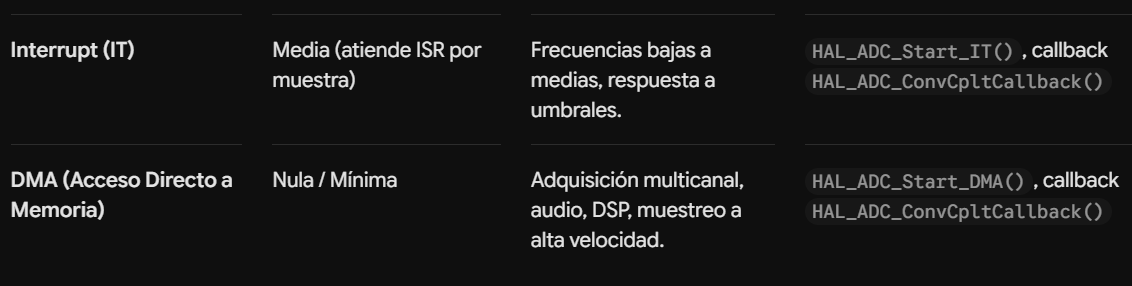

Ejemplo de implementación:
